# GPT Explorations 1 - Tiny TOEFL

## 1. But what really stand for GPT?
<div class='alert alert-block alert-info'>
A Generative Pre‑trained Transformer (GPT) is a type of large language model built on the transformer architecture, trained on massive amounts of text data to learn patterns of language. After pre‑training, it can generate coherent text, answer questions, and perform many language tasks by predicting the next word in a sequence.
</div>

## 2. Configuration
Here are the configurations of all GPT-2 models.

You will notice that I've added the Tiny and Mini selection for this notebook, while the rest of them are the size definitions from OpenAI.

In [1]:
GPT_CONFIGS = {
    "Tiny": {
        "emb_dim": 32,
        "n_layers": 2,
        "n_heads": 4
    },
    "Mini": {
        "emb_dim": 384,
        "n_layers": 6,
        "n_heads": 6
    },   
    "124M": {
        "emb_dim": 768,
        "n_layers": 12,
        "n_heads": 12
    },
    "355M": {
        "emb_dim": 1024,
        "n_layers": 24,
        "n_heads": 16
    },
    "774M": {
        "emb_dim": 1280,
        "n_layers": 36,
        "n_heads": 20
    },
    "1558M": {
        "emb_dim": 1600,
        "n_layers": 48,
        "n_heads": 25
    }
}

# Select model, we will use Tiny in this notebook.
model_size = "Tiny"

GPT_CONFIG = {
    "context_length": 128, # Original: 1024
    "vocab_size": 50257,
    "drop_rate": 0.1,
    "qkv_bias": False,
    **GPT_CONFIGS[model_size]
}

## 3. The Building Blocks of GPT
- ### Layer Normalization

In [2]:
import torch
import torch.nn as nn

In [3]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5 # Avoid division by 0.

        # They are registered to be model parameters, that the optimizer will update them while training
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self,x):
        # Calculate mean, variance, and then normalized data points.
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, correction=0)
        norm_x = (x-mean)/torch.sqrt(var+self.eps)
        return self.scale * norm_x + self.shift

$$\operatorname{LayerNorm}(x_i)=\gamma_i\frac{x_i-\mu}{\sqrt{\sigma^2+\epsilon}}+\beta_i$$

Where mean $\mu=\frac{1}{d}\sum_{i=1}^{d}x_i$

variance $\sigma^2=\frac{1}{d}\sum_{i=1}^{d}(x_i-\mu)^2$

And $\gamma_i$ and $\epsilon$ are trainable parameters

<div class="alert alert-block alert-info">
It basically changes the variance of batch input to 1 and the mean to 0.
</div>

This can help alleviate the effect of **gradient explosion** or **vanishing gradient**, also speeding up **convergence**.

`torch.nn.Parameter` is a special kind of tensor in PyTorch that tells the framework *“this is a trainable parameter of the model.”* When you assign a `Parameter` inside an `nn.Module`, it is automatically registered so that `model.parameters()` and optimizers know to update it during training.

In the `LayerNorm` example, the `scale` (γ) and `shift` (β) are defined as `Parameters`. They are selective, but this allows the model to adjust the normalized values flexibly instead of always keeping them fixed. Without `Parameter`, they would just be static tensors and never change.

-  ### Activation Function

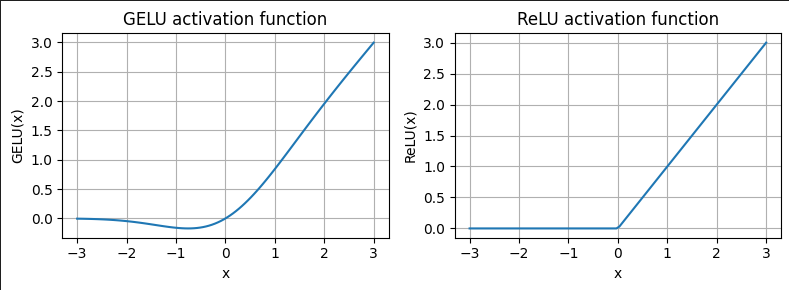


<div class="alert alert-block alert-info">

As we can see in the resulting plot, ReLU is a piecewise linear function that
outputs the input directly if it is positive; otherwise, it outputs zero.

GELU is a smooth, nonlinear function that approximates ReLU but with a non-zero gradient for negative values.
</div>

<div class="alert alert-block alert-warning">

The smoothness of GELU, as shown in the above figure, can lead to better optimization properties
during training, as it allows for more nuanced adjustments to the model's parameters.

In contrast, ReLU has a sharp corner at zero, which can sometimes make optimization harder,
especially in networks that are very deep or have complex architectures.

Moreover, unlike RELU, which outputs zero for any negative input, GELU allows for a small, non-zero output
for negative values.

This characteristic means that during the training process, neurons that
receive negative input can still contribute to the learning process, albeit to a lesser extent
than positive inputs.

</div>

In [4]:
class GELU(nn.Module):
    def __init__(self):
        super().__init__()
    def forward(self,x):
        return 0.5*x*(
            1 + torch.tanh(
                torch.sqrt(
                    (torch.tensor(2/torch.pi))
                ) * (x + 0.044715 * torch.pow(x,3))
            )
        )

This is the approximate version of $\text{GELU}$ that uses the hyperbolic tangent (`tanh`), used by GPT-2.

$\mathrm{GELU}(x) = \frac{1}{2}x\left(1 + \tanh\left(\sqrt{\frac{2}{\pi}}\left(x + 0.022715x^3\right)\right)\right)$

Fun Fact: PyTorch already has a GELU activation function for us to use:

```Python
import torch
import torch.nn.functional as F

# Exact GELU
exact = F.gelu(x, approximate="none")

# Approximate GELU
approx = F.gelu(x, approximate="tanh")
```

- ### Feed Forward Neural Network

In [5]:
class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4*cfg["emb_dim"]), # Expansion
            GELU(), # Activation
            nn.Linear(4*cfg["emb_dim"], cfg["emb_dim"]) # Contraction
        )
    def forward(self,x):
        return self.layers(x)

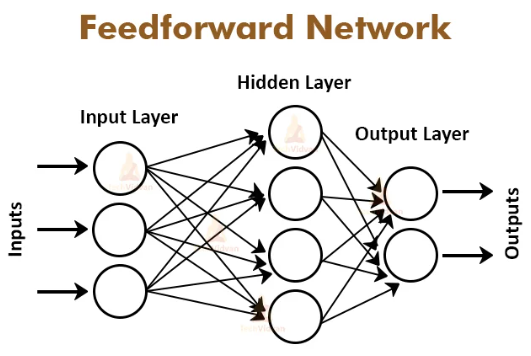


Feed forward neural network **expands** the input dimension as hidden layer(s)(one hidden layer, 4x dimensions in this case), and then **contract** back (into the input dimension in this case).

This allows the model a **rich exploration space**.

- ### Residual Connection
Residual connection means a direct gradient addition from the previous input layer to the new layer, which can prevent any gradient vanishing.

Let's start with an example network.

In [6]:
class ExampleDeepNeuralNetwork(nn.Module):
    def __init__(self, layer_sizes, use_shortcut):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(layer_sizes[0], layer_sizes[1]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[1], layer_sizes[2]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[2], layer_sizes[3]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[3], layer_sizes[4]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[4], layer_sizes[5]), GELU()),
        ])

    def forward(self, x):
        for layer in self.layers:
            # Compute the output of the current layer
            layer_output = layer(x)
            # Check if shortcut can be applied
            if self.use_shortcut and x.shape == layer_output.shape:
                x = x + layer_output # Residual connection
            else:
                x = layer_output     # No residual connection
        return x

Creating instances of two networks:
- one with shortcut connection
- one without

In [7]:
sample_input = torch.tensor([[1. , 0., -1.]])
model_without_shortcut = ExampleDeepNeuralNetwork(
    layer_sizes =[3,3,3,3,3,1], use_shortcut=False
)
model_with_shortcut = ExampleDeepNeuralNetwork(
    layer_sizes =[3,3,3,3,3,1], use_shortcut=True
)

Creating a function to represent gradients using MSE loss function:

In [8]:
def print_gradients(model, x):
    # Forward pass
    output = model(x)
    target = torch.tensor([[0.]])

    # Calculate loss based on how close the output to the target
    loss = nn.MSELoss()
    loss = loss(output, target)

    # Backward pass to calculate the gradients
    loss.backward()

    for name, param in model.named_parameters():
        if 'weight' in name:
            # print the mean absolute value of the weights
            print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")

In [9]:

print_gradients(model_without_shortcut, sample_input)
print("\n")
print_gradients(model_with_shortcut, sample_input)


layers.0.0.weight has gradient mean of 7.537713372585131e-06
layers.1.0.weight has gradient mean of 6.6943266574526206e-06
layers.2.0.weight has gradient mean of 1.1995322893199045e-05
layers.3.0.weight has gradient mean of 0.0005612541572190821
layers.4.0.weight has gradient mean of 0.005844397004693747


layers.0.0.weight has gradient mean of 0.12953758239746094
layers.1.0.weight has gradient mean of 0.2745901644229889
layers.2.0.weight has gradient mean of 0.05110092833638191
layers.3.0.weight has gradient mean of 0.1470821499824524
layers.4.0.weight has gradient mean of 1.880965232849121


As we can see based on the output of the print_gradients function, the gradients become
smaller as we progress from the last layer (layers.4) to the first layer (layers.0), which
is a phenomenon called the vanishing gradient problem.
<div class="alert alert-block alert-info">
With residual connection with a shortcut, the gradient is less 'vanished' compared to without.
</div>

#### Why backward pass to calculate gradient?

While training layers of neural networks, we want to know how much extent the output is different than desired value. So usually a loss function is implemented to see the difference between desired output and input.

In mathematics we know that in order to solve the gradient of a composite function, we have to use `chain rule`. In machine learning, each intermediate gradient can be repeated to calculate the next gradient using partial derivative of the output layer to one specific parameters. We have to continuously calculate partial derivatives until we reach the first parameter. This is called `backpropagation`.



A neural network is essentially one massive composite function. Let's look at a simple 3-layer path:

1. **Input:** $x$

2. **Hidden Layer:** $h = \sigma(w_1 \cdot x)$ (where $\sigma$ is an activation function)

3. **Output:** $y = w_2 \cdot h$

4. **Loss:** $L = (y_{\text{true}} - y)^2$

To adjust the weight $w_1$ to reduce the Loss ($L$), we need the gradient $\frac{\partial L}{\partial w_1}$. Using the Chain Rule, we "unzip" it from the end to the beginning:

$$
\frac{\partial L}{\partial w_1}
=
\underbrace{\frac{\partial L}{\partial y}}_{\text{Change in Loss per Output}}
\cdot
\underbrace{\frac{\partial y}{\partial h}}_{\text{Change in Output per Hidden}}
\cdot
\underbrace{\frac{\partial h}{\partial w_1}}_{\text{Change in Hidden per Weight}}
$$

The brilliance of Backpropagation is that it calculates these pieces from right to left (Loss $\rightarrow$ Input) and caches (saves) them.

Notice that if you have an even earlier weight $w_0$, its calculation would look like this:

$$
\frac{\partial L}{\partial w_0}
=
\underbrace{
\left(
\frac{\partial L}{\partial y}
\cdot
\frac{\partial y}{\partial h}
\cdot
\frac{\partial h}{\partial x}
\right)
}_{\text{Already computed for the previous weight!}}
\cdot
\frac{\partial x}{\partial w_0}
$$

By storing the result of the "chain" as it moves backward, the computer only has to perform a **local multiplication at each layer** rather than re-calculating the entire derivative from scratch.


- ### Multi Head Attention

In [10]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert (d_out % num_heads == 0), \
            "d_out must be divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads # Reduce the projection dim to match the desired output dim
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out) # Linear layer to combine head inputs
        self.dropout = nn.Dropout(dropout) # Floor division
        self.register_buffer(
            "mask",
            torch.triu(torch.ones(context_length, context_length), diagonal = 1)
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape

        keys = self.W_key(x) # Shape: (b, num_tokens, d_out)
        queries = self.W_query(x)
        values = self.W_value(x)

        # We implicitly split the matrix by adding a 'num_heads' dimension
        # Unroll the last dim: (b, num_tokens, d_out) -> (b, num_tokens, num_heads, head_dim)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)

        # Transpose: (b, num_tokens, num_heads, head_dim) -> (b, num_heads, num_tokens, head_dim)
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        # Compute scaled dot-product attention (self-attention) with a causal mask
        attn_scores = queries @ keys.transpose(2, 3) # Dot product for each head
        # (b, num_heads, num_tokens, num_tokens)

        attn_scores.masked_fill_(self.mask.bool()[:num_tokens, :num_tokens], -torch.inf)
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        # Shape: (b, num_tokens, num_heads, head_dim)
        context_vec = (attn_weights @ values).transpose(1,2)

        # Combine heads, where self.d_out = self.num_heads * self.head_dim
        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec)
        # Combine all heads back into one unified representation.

        return context_vec



## 4. The Transformer Block and the GPT Model

In [11]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in = cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"]
        )
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        # Residual connection for attention block
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)             # Shape (batch_size, num_tokens, emb_size)
        x = self.drop_shortcut(x)
        x = x + shortcut            # Add the original input back

        # Residual connection for feedforward block
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut

        return x

In [12]:
class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        nn.init.normal_(self.tok_emb.weight, mean=0.0, std=0.02)
        nn.init.normal_(self.pos_emb.weight, mean=0.0, std=0.01)
        self.drop_emb = nn.Dropout(cfg["drop_rate"])
        # creates a sequential stack of TransformerBlock modules equal to the number of layers specified in cfg.
        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])]
        )
        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False) # No bias
        # Projects the transformer's output into the vocabulary space of the tokenizer to generate logits for each token in the vocabulary.
        self.out_head.weight = self.tok_emb.weight # Weight tying
        # Thus, Input Embedding and Output Head will maintain a same weight

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

<div class="alert alert-block alert-success">
Let's now initialize the GPT model using the GPT_CONFIG
dictionary we pass into the cfg parameter and feed it with the batch text input.
</div>

In [13]:
torch.manual_seed(123) # For reproducibility
model = GPTModel(GPT_CONFIG)

import tiktoken
tokenizer = tiktoken.get_encoding("gpt2")
batch = []
txt1 = "Every effort moves you"
txt2 = "Every day holds a"
batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch = torch.stack(batch, dim=0)

out = model(batch)
print("Input batch: \n", batch)
print("\nOutput shape:", out.shape)
print(out)

Input batch: 
 tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])

Output shape: torch.Size([2, 4, 50257])
tensor([[[ 1.6850e-01,  9.0016e-02,  2.0620e-01,  ...,  1.1261e-01,
           2.5027e-02,  1.0151e-01],
         [ 1.0888e-01, -1.4180e-01,  1.0886e-01,  ...,  6.0762e-02,
           8.2389e-02,  1.2131e-01],
         [ 8.1925e-02, -9.7579e-02,  2.0677e-01,  ..., -4.6268e-02,
           3.1364e-02,  1.9644e-01],
         [ 1.1957e-01,  2.0930e-04,  7.8348e-02,  ...,  1.0561e-01,
          -7.8718e-02,  4.0058e-02]],

        [[ 5.4126e-02,  2.8685e-02,  1.8585e-01,  ...,  4.3360e-02,
           1.0425e-01,  1.2468e-01],
         [-8.5323e-02,  7.4844e-02,  1.2578e-01,  ...,  2.7839e-02,
           8.9440e-02, -5.2799e-02],
         [-1.0238e-01,  7.0186e-02, -4.4026e-02,  ..., -1.0140e-02,
          -1.9282e-01,  1.4655e-01],
         [-2.0756e-02,  8.7313e-02,  2.6493e-01,  ..., -1.0908e-01,
          -1.5388e-01,  1.1361e-01]]], grad_fn=<UnsafeViewBackward0>)


In [14]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:,}")

Total number of parameters: 1,637,600


In [15]:
print("Token embedding layer shape:", model.tok_emb.weight.shape)
print("Output layer shape:", model.out_head.weight.shape)

Token embedding layer shape: torch.Size([50257, 32])
Output layer shape: torch.Size([50257, 32])


In [16]:
total_size_bytes = total_params * 4
total_size_mb = total_size_bytes / (1024 * 1024)
print(f"Total size of the model: {total_size_mb:.2f} MB")

Total size of the model: 6.25 MB


## 5. Generating text from output tokens

<div class="alert alert-block alert-success">
Let us implement the token-generation process as follows:
</div>

This is known as `Greedy Search`

In [17]:
def generate_text_simple(model, idx, max_new_tokens, context_size):
    
    for _ in range(max_new_tokens):
        # Crop current context if it exceeds the supported context size
        idx_cond = idx[:, -context_size:]
        # Select all rows (batches), slice columns (tokens) from end to cound backwards.

        # Get the predictions
        with torch.no_grad(): # The model won't need to update parameters during inference
            logits = model(idx_cond) # shape (batch, num_tokens, vocab_size)

        # Focus only on the last time step
        # Shape contverted to: (batch, vocab_size)
        logits = logits[:, -1, :]
        # Keep all batches; selects only the last position in the sequence; keeps the entire vocabulary

        # Get the idx of the vocab entry with the highest probability value
        # aka greedy selection
        idx_next = torch.argmax(logits, dim=-1, keepdim=True) # shape (batch, 1)

        # Append sampled index to the running sequence
        idx = torch.cat((idx, idx_next), dim=1) # (batch, n_tokens+1)

    return idx

<div class="alert alert-block alert-success">
Let's now try out the generate_text_simple function with the "Hello, I am" context
as model input
</div>

In [18]:
start_context = "Hello, I am"
encoded = tokenizer.encode(start_context)
print("encoded:", encoded)
encoded_tensor = torch.tensor(encoded).unsqueeze(0)
# Insert a new dimension at dimension 0.  Shape: (batch_size, n_tokens)
# Because the model will always need a batch to process
print("encoded_tensor.shape", encoded_tensor.shape)

encoded: [15496, 11, 314, 716]
encoded_tensor.shape torch.Size([1, 4])


<div class="alert alert-block alert-success">
Next, we put the model into .eval() mode, which disables random components like
dropout, which are only used during training, and use the generate_text_simple function
on the encoded input tensor:
</div>
<div class="alert alert-block alert-info">

We disable dropout since we are not training the model

</div>


In [19]:
model.eval()
out = generate_text_simple(
    model=model,
    idx=encoded_tensor,
    max_new_tokens=6,
    context_size=GPT_CONFIG["context_length"]
)
print("Output:", out)
print("output length:", len(out[0]))

Output: tensor([[15496,    11,   314,   716, 18987, 18987, 18987, 39285, 10657, 45300]])
output length: 10


In [20]:
decoded_text = tokenizer.decode(out.squeeze(0).tolist())
print(decoded_text)

Hello, I am Users Users Users Casting wounded Wem


<div class="alert alert-block alert-info">

As we can see, based on the preceding output, the model generated gibberish, which is not
at all coherent text. 

</div>
The reason why the model is unable to produce coherent text is that we haven't trained it yet. 

So far, we just
implemented the GPT architecture and initialized a GPT model instance with initial random
weights.

## 6. Evaluating Generative Text Models
As you can see, in the previous section the model is not producing coherent text.

We are going to explore metrics to calculate a **loss metric** for the generated outputs that we can use to measure the training process.

Let's start with an input and target pair.


In [21]:
inputs = torch.tensor([[16833, 3626, 6100],   # ["every effort moves",
                       [40,    1107, 588]])   #  "I really like"]

targets = torch.tensor([[3626, 6100, 345  ],  # [" effort moves you",
                        [1107,  588, 11311]]) #  " really like chocolate"]

In [22]:
with torch.no_grad():
    logits = model(inputs)

print(logits.shape)

torch.Size([2, 3, 50257])


In [23]:
token_ids = torch.argmax(logits, dim=-1, keepdim=True)
print("Token IDs:\n", token_ids)

Token IDs:
 tensor([[[39370],
         [39370],
         [39370]],

        [[19382],
         [14156],
         [46767]]])


In [24]:
def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(text, allowed_special={'<|endoftext|>'})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0) # add batch dimension
    return encoded_tensor

def token_ids_to_text(token_ids, tokenizer):
    flat = token_ids.squeeze(0) # remove batch dimension
    return tokenizer.decode(flat.tolist())

print(f"Target batch 1: {token_ids_to_text(targets[0], tokenizer)}")
print(f"Outputs batch 1: {token_ids_to_text(token_ids[0].flatten(), tokenizer)}")

Target batch 1:  effort moves you
Outputs batch 1: riksriksriks


### 1. Cross-entropy loss

Although only relying on logits without normalization can produce identical result with slightly less computational power, we have to consider probabilities while dealing with loss functions.

In [25]:
probas = torch.softmax(logits, dim=-1) # Probability of each token in vocabulary
text_idx = 0
target_probas_1 = probas[text_idx, [0, 1, 2], targets[text_idx]]
print("Text 1:", target_probas_1)

text_idx = 1
target_probas_2 = probas[text_idx, [0, 1, 2], targets[text_idx]]
print("Text 2:", target_probas_2)

Text 1: tensor([2.1584e-05, 2.0868e-05, 1.8281e-05])
Text 2: tensor([2.3913e-05, 2.5637e-05, 1.9821e-05])


<div class="alert alert-block alert-warning">

We want to maximize all these values, bringing them close to a probability of 1.
    
In mathematical optimization, it is easier to maximize the logarithm of the probability score than the probability score itself.

</div>

<div class="alert alert-block alert-success">

PyTorch already implements a cross_entropy function that carries out the previous steps

Before we apply the cross_entropy function, let's check the shape of the logits and targets

</div>

In [26]:
# Logits have shape (batch_size, num_tokens, vocab_size)
print("Logits shape:", logits.shape)

# Targets have shape (batch_size, num_tokens)
print("Targets shape:", targets.shape)

Logits shape: torch.Size([2, 3, 50257])
Targets shape: torch.Size([2, 3])


<div class="alert alert-block alert-success">

For the cross_entropy function in PyTorch, we want to flatten these tensors by combining them over the batch dimension:


</div>

In [27]:
logits_flat = logits.flatten(0, 1)
targets_flat = targets.flatten()

print("Flattened logits:", logits_flat.shape)
print("Flattened targets: ", targets_flat.shape)

Flattened logits: torch.Size([6, 50257])
Flattened targets:  torch.Size([6])


<div class="alert alert-block alert-info">

Note that the targets are the token IDs, which also represent the index positions in the logits tensors that we want to maximize.
    
The cross_entropy function in PyTorch will automatically take care of applying the softmax and log-probability computation internally over those token indices in the logits that are to be maximized

</div>

In [28]:
loss = torch.nn.functional.cross_entropy(logits_flat, targets_flat)
print(loss)

tensor(10.7453)


### 2. Perplexity

<div class="alert alert-block alert-success">

A concept related to the cross-entropy loss is the perplexity of an LLM.

The perplexity is simply the exponential of the cross-entropy loss.

</div>

In [29]:
perplexity = torch.exp(loss)
print(perplexity)

tensor(46411.2188)


<div class="alert alert-block alert-info">

The perplexity is often considered more interpretable because it can be understood as the effective vocabulary size that the model is uncertain about at each step (in the example above, that'd be 48,725 words or tokens).

In other words, perplexity provides a measure of how well the probability distribution predicted by the model matches the actual distribution of the words in the dataset.
    
Similar to the loss, a lower perplexity indicates that the model predictions are closer to the actual distribution
    
</div>

## 7. Calculating the training and validation set losses
<div class="alert alert-block alert-success">

We are going to use a relatively small dataset for the training process for educational purposes.

To be honest, writing requires quite amount of effort for skills and proficiency. So while I was having Toefl writing classes, I have written a bunch of writing practices. Now I am going to use those as the dataset to train the model.🤣
</div>

In [30]:
import os
import urllib.request

file_path = "TOEFL Writing.txt"

if not os.path.exists(file_path):
    print(f"Cannot find the dataset {file_path}")
else:
    with open(file_path, "r") as file:
        text_data = file.read()

AHH, a sneak peak of one of the highly stylized written passages!

In [31]:
print(text_data[:99])

<|endoftext|>
[INTEGRATED_WRITING]
The reading proposes three hypotheses about the functions of tre


In [32]:
total_characters = len(text_data)
total_tokens = len(tokenizer.encode(text_data,allowed_special={"<|endoftext|>"}))

print("Characters:", total_characters)
print("Tokens:", total_tokens)

Characters: 25770
Tokens: 5097


<div class="alert alert-block alert-warning">

Next, we divide the dataset into a training and a validation set and use the data loaders from chapter 2 to prepare the batches for LLM training.
    
Since we train the LLM to predict the next word in the text, the targets look the same as these inputs, except that the targets are shifted by one position    
</div>

### DataLoader

In [33]:
from torch.utils.data import Dataset, DataLoader

class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        # Tokenize the entire text
        token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})

        # Use a sliding window to chunk the book into overlapping sequences of max_length
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1: i + max_length + 1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]


def create_dataloader_v1(txt, batch_size=4, max_length=256, 
                         stride=128, shuffle=True, drop_last=True,
                         num_workers=0):

    # Initialize the tokenizer
    tokenizer = tiktoken.get_encoding("gpt2")

    # Create dataset
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)

    # Create dataloader
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers
    )

    return dataloader

In [34]:
# Train/validation ratio
train_ratio = 0.80
split_idx = int(train_ratio * len(text_data))
train_data = text_data[:split_idx]
val_data = text_data[split_idx:]


train_loader = create_dataloader_v1(
    train_data,
    batch_size=2,
    max_length=GPT_CONFIG["context_length"],
    stride=int(GPT_CONFIG["context_length"]/2),
    drop_last=True,
    shuffle=True,
    num_workers=0
)

val_loader = create_dataloader_v1(
    val_data,
    batch_size=2,
    max_length=GPT_CONFIG["context_length"],
    stride=GPT_CONFIG["context_length"],
    drop_last=False,
    shuffle=False,
    num_workers=0
)

In [35]:
# Sanity check

if total_tokens * (train_ratio) < GPT_CONFIG["context_length"]:
    print(
        "Not enough space for the training loader."
        "Try to lower the context length or increase the training ratio"
    )
if total_tokens * (1-train_ratio) < GPT_CONFIG["context_length"]:
    print(
        "Not enough space for the training loader."
        "Try to lower the context length or increase the training ratio"
    )

<div class="alert alert-block alert-success">

Two optional checks that the data was loaded correctly:

</div>

In [36]:
print("Train loader:")
for x, y in train_loader:
    print(x.shape, y.shape)

print("\nValidation loader:")
for x, y in val_loader:
    print(x.shape, y.shape)

print(len(train_loader))
print(len(val_loader))


Train loader:
torch.Size([2, 128]) torch.Size([2, 128])
torch.Size([2, 128]) torch.Size([2, 128])
torch.Size([2, 128]) torch.Size([2, 128])
torch.Size([2, 128]) torch.Size([2, 128])
torch.Size([2, 128]) torch.Size([2, 128])
torch.Size([2, 128]) torch.Size([2, 128])
torch.Size([2, 128]) torch.Size([2, 128])
torch.Size([2, 128]) torch.Size([2, 128])
torch.Size([2, 128]) torch.Size([2, 128])
torch.Size([2, 128]) torch.Size([2, 128])
torch.Size([2, 128]) torch.Size([2, 128])
torch.Size([2, 128]) torch.Size([2, 128])
torch.Size([2, 128]) torch.Size([2, 128])
torch.Size([2, 128]) torch.Size([2, 128])
torch.Size([2, 128]) torch.Size([2, 128])
torch.Size([2, 128]) torch.Size([2, 128])
torch.Size([2, 128]) torch.Size([2, 128])
torch.Size([2, 128]) torch.Size([2, 128])
torch.Size([2, 128]) torch.Size([2, 128])
torch.Size([2, 128]) torch.Size([2, 128])
torch.Size([2, 128]) torch.Size([2, 128])
torch.Size([2, 128]) torch.Size([2, 128])
torch.Size([2, 128]) torch.Size([2, 128])
torch.Size([2, 128])

In [37]:
train_tokens = 0
for input_batch, target_batch in train_loader:
    train_tokens += input_batch.numel()

val_tokens = 0
for input_batch, target_batch in val_loader:
    val_tokens += input_batch.numel()

print("Training tokens:", train_tokens)
print("Validation tokens:", val_tokens)
print("All tokens:", train_tokens + val_tokens)

Training tokens: 7936
Validation tokens: 896
All tokens: 8832


<div class="alert alert-block alert-success">

Next, we implement a utility function to calculate the cross-entropy loss of a given batch.

In addition, we implement a second utility function to compute the loss for a user-specified number of batches in a data loader.
</div>

In [38]:
def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    logits = model(input_batch)
    loss = torch.nn.functional.cross_entropy(logits.flatten(0, 1), target_batch.flatten())
    return loss

def calc_loss_loader(data_loader, model, device, num_batches=None):
    total_loss = 0.
    if len(data_loader) == 0:
        return float("nan")
        # Avoid division by zero
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        # Ensure num_batches (if specified) is less than actual batch number the length of the dataloader.
        num_batches = min(num_batches, len(data_loader))
    
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()
            # item() to significantly reduce memory footprint (tensor -> float)
        else:
            break
    return total_loss / num_batches

<div class="alert alert-block alert-info">

If you have a machine with a CUDA-supported GPU, the LLM will train on the GPU without making any changes to the code.
    
Via the device setting, we ensure that the data is loaded onto the same device as the LLM model.
    
</div>

In [39]:
#device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Note:
# Uncommenting the following lines will allow the code to run on Apple Silicon chips, if applicable,
# which is approximately 2x faster than on an Apple CPU (as measured on an M3 MacBook Air).
# However, the resulting loss values may be slightly different.

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available(): # Apple Silicon (M series chip) Metal Performance Shader
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Using {device} device.")


model.to(device) # no assignment model = model.to(device) necessary for nn.Module classes


with torch.no_grad(): # Disable gradient tracking for efficiency because we are not training, yet
    train_loss = calc_loss_loader(train_loader, model, device)
    val_loss = calc_loss_loader(val_loader, model, device)

print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Using mps device.
Training loss: 10.828784388880576
Validation loss: 10.822479963302612


## 8. Training loop for the LLM

<div class="alert alert-block alert-info">

The evaluate_model function calculates the loss over the training and
validation set while ensuring the model is in evaluation mode with gradient tracking and
dropout disabled when calculating the loss over the training and validation sets
    
</div>

In [40]:
def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
    model.train()
    return train_loss, val_loss

<div class="alert alert-block alert-info">

The generate_and_print_sample function is a convenience function that we use to track whether the model improves during the training. 

In particular, the generate_and_print_sample function takes a text snippet (start_context) as input,
converts it into token IDs, and feeds it to the LLM to generate a text sample using the
generate_text_simple function we used earlier
    
</div>

In [41]:
def generate_and_print_sample(model, tokenizer, device, start_context):
    model.eval()
    context_size = model.pos_emb.weight.shape[0]
    encoded = text_to_token_ids(start_context, tokenizer).to(device)
    with torch.no_grad():
        token_ids = generate_text_simple(
            model=model, idx=encoded,
            max_new_tokens=50, context_size=context_size
        )
    decoded_text = token_ids_to_text(token_ids, tokenizer)
    print(decoded_text.replace("\n", " "))  # Compact print format
    model.train()

In [42]:
def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs,
                       eval_freq, eval_iter, start_context, tokenizer, early_stopping):
    # Early stopping variables
    best_val_loss = float("inf")
    best_epoch = 0
    patience = 5
    counter = 0

    # Initialize lists to track losses and tokens seen
    train_losses, val_losses, track_tokens_seen = [], [], []
    tokens_seen, global_step = 0, -1

    # Main training loop
    for epoch in range(num_epochs):
        model.train()

        for input_batch, target_batch in train_loader:
            optimizer.zero_grad()

            loss = calc_loss_batch(input_batch, target_batch, model, device)
            loss.backward()
            optimizer.step()

            tokens_seen += input_batch.numel()
            global_step += 1

            # Print training loss after every step
            print(f"Step {global_step:06d} | Train Loss: {loss.item():.4f}")

        # Evaluate after every epoch
        train_loss, val_loss = evaluate_model(
            model, train_loader, val_loader, device, eval_iter
        )

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        track_tokens_seen.append(tokens_seen)

        print(f"\n{'='*50}")
        print(f"Epoch {epoch+1}/{num_epochs} Completed")
        print(f"Train Loss: {train_loss:.4f}")
        print(f"Validation Loss: {val_loss:.4f}")
        print(f"{'='*50}")

        # Generate sample text after every epoch
        print(f"\nGenerated Text (Epoch {epoch+1}):")

        generate_and_print_sample(
            model, tokenizer, device, start_context
        )

        print("\n")

        # Early stopping logic
        if early_stopping:
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_epoch = epoch + 1
                counter = 0
                # torch.save(model.state_dict(), "best_model.pth")
            else:
                counter += 1

            if counter >= patience:
                print(f"Early stopping at epoch {epoch + 1}")
                break

    if early_stopping:
        print(f"Best epoch: {best_epoch}")
        print(f"Best validation loss: {best_val_loss:.4f}")

    return train_losses, val_losses, track_tokens_seen, epoch

<div class="alert alert-block alert-success">

Let's see this all in action by training a GPTModel instance for 10 epochs using an AdamW
optimizer and the train_model_simple function we defined earlier.
</div>

Execute the following cell will start training the GPT-2 model based on the selection of the model.

In [43]:
import time
start_time = time.time()

model = GPTModel(GPT_CONFIG)
model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0022, weight_decay=0.01)

num_epochs = 200
train_losses, val_losses, tokens_seen, final_epoch = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=5, eval_iter=None,
    start_context=text_data[0:20], tokenizer=tokenizer,early_stopping=False
)


end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")

Step 000000 | Train Loss: 10.8307
Step 000001 | Train Loss: 10.7828
Step 000002 | Train Loss: 10.7462
Step 000003 | Train Loss: 10.6884
Step 000004 | Train Loss: 10.6157
Step 000005 | Train Loss: 10.5277
Step 000006 | Train Loss: 10.4386
Step 000007 | Train Loss: 10.4013
Step 000008 | Train Loss: 10.2331
Step 000009 | Train Loss: 10.1811
Step 000010 | Train Loss: 10.1663
Step 000011 | Train Loss: 10.0222
Step 000012 | Train Loss: 9.8413
Step 000013 | Train Loss: 9.7876
Step 000014 | Train Loss: 9.7035
Step 000015 | Train Loss: 9.4555
Step 000016 | Train Loss: 9.6018
Step 000017 | Train Loss: 9.4016
Step 000018 | Train Loss: 9.2890
Step 000019 | Train Loss: 9.3112
Step 000020 | Train Loss: 9.1388
Step 000021 | Train Loss: 8.9364
Step 000022 | Train Loss: 8.9044
Step 000023 | Train Loss: 8.6281
Step 000024 | Train Loss: 8.5526
Step 000025 | Train Loss: 8.5862
Step 000026 | Train Loss: 8.3468
Step 000027 | Train Loss: 8.4783
Step 000028 | Train Loss: 8.2531
Step 000029 | Train Loss: 8.189

As we can see, the Training loss is constantly decresing, while the validation loss increases from the beginning of the training process

This indicates the model is overfitting, as the TOEFL corpus for the model is far not enough to learn the general ideas of language -- instead, the model just memorize the original text.

**Although the Training Loss is decreasing, the model still fails to obtain langauge generalization**

<div class="alert alert-block alert-success">

Let's create a simple plot that shows the training and validation set losses side by side
</div>

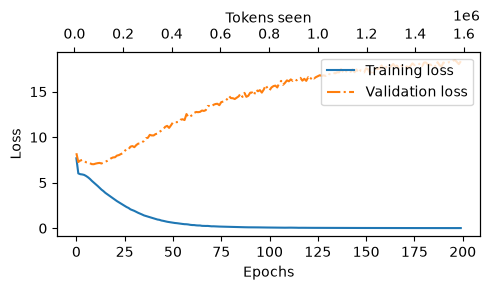

In [44]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    fig, ax1 = plt.subplots(figsize=(5,3))

    # Plot training and validation loss against epochs
    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(epochs_seen, val_losses, linestyle="-.", label="Validation loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True)) # Only show integer labels on x-axis

    # Create a second x-axis for tokens seen
    ax2 = ax1.twiny() # Sharing the same y-axis as ax1
    ax2.plot(tokens_seen, train_losses, alpha=0) # Invisible plot for aligning ticks
    ax2.set_xlabel("Tokens seen")

    fig.tight_layout() # Adjust layout to make room
    plt.show()

epochs_tensor = torch.linspace(0, final_epoch, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)


<div class='alert alert-block alert-success'>

With that little data, the model will certainly overfit.

In fact, I deliberately made it over fit to see what will happen.
</div>

In [45]:
model.eval()

GPTModel(
  (tok_emb): Embedding(50257, 32)
  (pos_emb): Embedding(128, 32)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=32, out_features=32, bias=False)
        (W_key): Linear(in_features=32, out_features=32, bias=False)
        (W_value): Linear(in_features=32, out_features=32, bias=False)
        (out_proj): Linear(in_features=32, out_features=32, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=32, out_features=128, bias=True)
          (1): GELU()
          (2): Linear(in_features=128, out_features=32, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=32, out_featu

<div class="alert alert-block alert-success">

Let's plug the GPTModel instance (model) into the generate_text_simple function,
which uses the LLM to generate one token at a time:
</div>

In [46]:
tokenizer = tiktoken.get_encoding("gpt2")

model.to('cpu')

def try_model(input):
    token_ids = generate_text_simple(
        model=model,
        idx=text_to_token_ids(input, tokenizer),
        max_new_tokens=25,
        context_size=GPT_CONFIG["context_length"]
    )

    print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

try_model("<|endoftext|>\n[ACADEMIC_DISCUSSION]\nFrom")

Output text:
 <|endoftext|>
[ACADEMIC_DISCUSSION]
From my perspective, mainly because two reasonsATED_DISCUSSION]
From my perspective, I firmly believe believe believe to


## 9. Output Enhancements

In [47]:
def generate(model, idx, max_new_tokens, context_size, temperature=0.0, top_k=None, eos_id=None):

    # For-loop is the same as before: Get logits and only focus on the last time step
    for _ in range (max_new_tokens):
        idx_cond = idx[:, -context_size:]
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :]

        # New: Filter logits with top_k sampling
        if top_k is not None:
            # Keep only top_k values
            top_logits, _ = torch.topk(logits, top_k)
            min_val = top_logits[:, -1]
            logits = torch.where(
                logits < min_val,
                torch.tensor(float("-inf")).to(logits.device),
                logits
            )

        # New: Apply temperature scaling
        if temperature > 0.0:
            logits = logits / temperature

            #Apply softmax to get probabilities
            probs = torch.softmax(logits, dim=-1) # (batch_size, context_len)

            # Sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1) # (batch_size, 1)

        # Otherwise same as before: get index of the vocab entry wit hthe highest logits value
        else:
            idx_next = torch.argmax(logits, dim=-1, keepdim=True) # (batch_size, 1)

        if idx_next == eos_id: #Stop generating early if end-of-sequence token is encountered and eos_id is specified
            break

        #Same: append sampled index to the running sequence
        idx =torch.cat((idx, idx_next), dim=-1) # (batch_size, num_tokens+1)
    return idx



In [48]:
torch.manual_seed(123)

model.to('cpu')

def try_model(input, new_tokens, temperature):
    token_ids = generate(
        model=model,
        idx=text_to_token_ids(input, tokenizer),
        max_new_tokens=new_tokens,
        context_size=GPT_CONFIG["context_length"],
        top_k=25,
        temperature=temperature
    )

    print("Output text:")
    print(token_ids_to_text(token_ids, tokenizer))

try_model("<|endoftext|>\n[ACADEMIC_DISCUSSION]\nFrom my perspective", new_tokens=150, temperature=1.4)

Output text:
<|endoftext|>
[ACADEMIC_DISCUSSION]
From my perspective, I agree for, take instant noodles as an example about their stability for firms to do list of the sauces and instant people support to do it is against, since as areatable, and return to do them. The constant ways, take take support extra our vertical than long purchase of releasing releasing releasing spaces that can help forgetting them serves for university, the younger energy degree. They can force students.
To begin with, though and the spread for this the function. These change or use refeteete and food, not when The professor none of these musical implication.
Additionally, online payment has said space station. To be fully develop their own own immense age. To be states states can evaluate those who eventually to help us to clarify, support


In [49]:
for temp in [0.0, 0.7, 1.0, 1.5, 2.0]:
    print('='*20)
    print(f"Result of temperature {temp}:")
    text='''<|endoftext|>
[ACADEMIC_DISCUSSION]
Government, personally, should provide support to space exploration, mainly because two reasons:'''
    try_model(text, new_tokens=150, temperature=temp)

Result of temperature 0.0:
Output text:
<|endoftext|>
[ACADEMIC_DISCUSSION]
Government, personally, should provide support to space exploration, mainly because two reasons: The constant intentional innovation and reserves more time for their constant intentional innovation which is the professor, space exploration requires intentional innovation which challenges what the human race can do, and, most importantly, to expand our boundaries. Therefore, government promoting them can provide immense implication. Astronomy is a subject that requires science skills, and what government can do is to constantly develop, support and expand the limits of science skills we have. Therefore, space exploration can serve as a good step towards our limits.



Government, support to the professor can be more more more more more more more more more more more more more more more more more more more more more more more more more more more more more more more more more more more more more more more more more

Since we are just training this model for continuing the same exact passages, we are going to see its accuracy on that mission.

In [50]:
model.eval()

token_ids = tokenizer.encode(
    text_data,
    allowed_special={"<|endoftext|>"}
)

# 使用训练数据的前 30 个 Token
prompt_ids = token_ids[:30]

device = next(model.parameters()).device

idx = torch.tensor(
    prompt_ids,
    dtype=torch.long,
    device=device
).unsqueeze(0)

with torch.no_grad():
    for _ in range(100):
        idx_cond = idx[:, -GPT_CONFIG["context_length"]:]

        logits = model(idx_cond)[:, -1, :]

        # Greedy decoding
        next_token = torch.argmax(
            logits,
            dim=-1,
            keepdim=True
        )

        idx = torch.cat([idx, next_token], dim=1)

generated_ids = idx[0].cpu().tolist()

expected_ids = token_ids[30:130]
predicted_ids = generated_ids[30:130]

correct = sum(
    a == b for a, b in zip(predicted_ids, expected_ids)
)

accuracy = correct / len(expected_ids)

print(f"Exact Match Accuracy: {accuracy:.2%}")

print("\nExpected:")
print(tokenizer.decode(expected_ids))

print("\nGenerated:")
print(tokenizer.decode(predicted_ids))

Exact Match Accuracy: 99.00%

Expected:
 they are all problematic.

To begin with, according to the reading, the cypress trees live in soil with low oxygen concentration, so that they use tree knees for extra oxygen supply. On the other hand, the professor disagreed with this idea by explaining a test. Scientists placed cypress tree knees in a closed chamber, and they measured the oxygen level inside over time. To their surprise, the oxygen level didn't change much, indicating they absorbed little oxygen, opposing the expected outcome, like

Generated:
 they are all problematic.

To begin with, according to the reading, the cypress trees live in soil with low oxygen concentration, so that they use tree knees for extra oxygen supply. On the other hand, the professor disagreed with this idea by explaining a test. Scientists placed cypress tree knees in a closed chamber, and they measured the oxygen level inside over time. To their surprise, the oxygen level didn't change much, indicating

In [51]:
first_error = next(
    (
        i for i, (pred, actual)
        in enumerate(zip(predicted_ids, expected_ids))
        if pred != actual
    ),
    None
)

print("First error position:", first_error)

if first_error is not None:
    print("Expected:",
          repr(tokenizer.decode([expected_ids[first_error]])))
    print("Predicted:",
          repr(tokenizer.decode([predicted_ids[first_error]])))

First error position: 99
Expected: ' like'
Predicted: ' the'


Teacher-forced accurace measures when the correct context from the original text is provided at every step, is it possible to predict the next token?

In [52]:
model.eval()

ids = torch.tensor(
    token_ids[:130],
    dtype=torch.long,
    device=next(model.parameters()).device
)

predictions = []

with torch.no_grad():
    for i in range(30, 130):
        context = ids[max(0, i-128):i].unsqueeze(0)
        logits = model(context)
        predictions.append(logits[0, -1].argmax().item())

teacher_accuracy = sum(
    p == t for p, t in zip(predictions, token_ids[30:130])
) / 100

print(f"Teacher-forced accuracy: {teacher_accuracy:.2%}")

Teacher-forced accuracy: 99.00%


<div class="alert alert-block alert-success">
We can observe the pattern that, the model will only output a specific snippet of TOFEL writing written by me with occasional grammar mistakes, even with very different inputs.
</div>

Interestingly, the output is highly concentrated on a set of specific snippets. 

## 10. Save the model

In [53]:
def save_model():
    chioce_savemodel = input("Save Model? (y/n)").lower().strip()
    if chioce_savemodel == 'y':
        model_name = input("Model Name:")
        torch.save(model.state_dict(), f"{model_name}.pth")

save_model()

<div class="alert alert-block alert-success">

If we plan to continue pretraining a model later, for example, using the
train_model_simple function we defined earlier in this chapter, saving the optimizer state
is also recommended.
</div>


Adaptive optimizers such as AdamW store additional parameters for each model weight.
AdamW uses historical data to adjust learning rates for each model parameter dynamically.
                                                   
Without it, the optimizer resets, and the model may learn suboptimally or even fail to
converge properly, which means that it will lose the ability to generate coherent text. 

Using
torch.save, we can save both the model and optimizer state_dict contents as follows:

In [54]:
'''optimizer = torch.optim.AdamW(model.parameters(), lr=0.0004, weight_decay=0.1)

torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    }, 
    "model_and_optimizer.pth"
)'''

'optimizer = torch.optim.AdamW(model.parameters(), lr=0.0004, weight_decay=0.1)\n\ntorch.save({\n    "model_state_dict": model.state_dict(),\n    "optimizer_state_dict": optimizer.state_dict(),\n    }, \n    "model_and_optimizer.pth"\n)'

Then, we can restore the model and optimizer states as follows by first loading the saved
data via torch.load and then using the load_state_dict method:

In [55]:
'''
checkpoint = torch.load("model_and_optimizer.pth")
model = GPTModel(GPT_CONFIG_124M)
model.load_state_dict(checkpoint["model_state_dict"])
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=0.1)
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
model.train();
'''

'\ncheckpoint = torch.load("model_and_optimizer.pth")\nmodel = GPTModel(GPT_CONFIG_124M)\nmodel.load_state_dict(checkpoint["model_state_dict"])\noptimizer = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=0.1)\noptimizer.load_state_dict(checkpoint["optimizer_state_dict"])\nmodel.train();\n'

<div class="alert alert-block alert-success">

However, in this notebook, we are going to just test the model and this model is nowhere near practical use.
</div>

## 11. Discoveries

It is noteworthy that the starting point for GPT-2 using AdamW optimizer has a learning rate 0.0004

I used `Mini` and `Tiny` variants of models, and discovered that:

- `Mini` requires less learning rate to converge.

- `Mini` converges slower with the same learning rate.

- `Tiny` is good for scenario when the text corpus is so small.

You can modify the training data to `the-verdict.txt` and try again!